#ANTECEDENTES

In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol
      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

#MOLÉCULA

Este código utiliza la función Chem.MolFromSmiles de la librería RDKit para crear un objeto de molécula a partir de una cadena SMILES. En este caso, la línea activa define la molécula de Oseltamivir. La línea comentada es un ejemplo para Naproxeno. Finalmente, la última línea molecule simplemente muestra la representación del objeto molécula creado en el notebook.


1- smile a mol

2- agregar hidrógenos

3- embed 'ajuste'

[intriducción a rdkit](https://www.rdkit.org/docs/GettingStartedInPython.html)

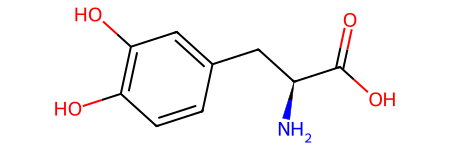

In [49]:
# molecule = Chem.MolFromSmiles('C[C@@H](C1=CC2=C(C=C1)C=C(C=C2)OC)C(=O)O') #naproxeno
molecule= Chem.MolFromSmiles("C1=CC(=C(C=C1C[C@@H](C(=O)O)N)O)O") #oseltamivir
molecule

Este código utiliza la función Chem.AddHs de RDKit para agregar átomos de hidrógeno explícitos a la molécula previamente definida (molecule). El resultado, que es la molécula con los hidrógenos añadidos, se guarda en una nueva variable llamada molecule_H. La segunda línea simplemente muestra esta nueva molécula en el output.

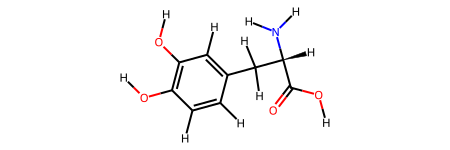

In [50]:
molecule_H = Chem.AddHs(molecule)
molecule_H

Este código utiliza la función EmbedMolecule del módulo AllChem de RDKit para generar una conformación 3D para la molécula molecule_H. El valor devuelto, molecule_embed, indica si la generación fue exitosa o no. Un valor de 0 generalmente significa que se encontró una conformación.

In [51]:
molecule_embed = AllChem.EmbedMolecule(molecule_H)
molecule_embed

0

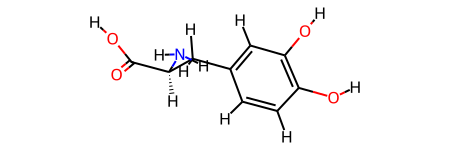

In [52]:
molecule_H

# py3Dmol

py3Dmol es una biblioteca de Python que funciona como un envoltorio (wrapper) para la biblioteca de JavaScript 3Dmol.js. Su propósito principal es permitir la visualización interactiva en 3D de datos moleculares (como proteínas y ligandos) directamente dentro de entornos de Python, como los cuadernos Jupyter.

Este código utiliza el módulo rdDistGeom de RDKit para generar una conformación tridimensional de la molécula molecule_H. Primero, crea un objeto ps que utiliza el algoritmo ETDG para la generación de conformaciones. Luego, se establece ps.clearConfs = False, lo que indica que no se deben borrar las conformaciones existentes. Finalmente, rdDistGeom.EmbedMolecule(molecule_H, ps) genera la conformación 3D para molecule_H usando los parámetros definidos en ps, y el identificador de esta conformación se guarda en la variable cid.

In [53]:
ps = rdDistGeom.ETDG()#ETKDG(), ETDG(), ETKDGv3()
ps.clearConfs= False
cid = rdDistGeom.EmbedMolecule(molecule_H,ps) #conformers id cid

In [54]:
cid

1

Este código muestra el valor de la variable cid. La variable cid almacena el identificador de la conformación 3D que se generó para la molécula en el paso anterior, utilizando rdDistGeom.EmbedMolecule. Actualmente, su valor es 1.

In [47]:
cid #tenemos dos confórmeros el 0 (global) y el 1 (local)

1

Este código crea una visualización 3D de la molécula molecule_H utilizando la librería py3Dmol. Primero, inicializa un visor con un tamaño de 700x700 píxeles. Luego, asegura que no haya modelos previos y añade la molécula molecule_H al visor, específicamente el confórmero con confId=0. Configura el estilo de visualización de la molécula a 'stick' con un esquema de colores 'greenCarbon', ajusta el zoom para que la molécula se vea completamente y finalmente muestra la visualización en el notebook.

Imprimimos el primer conformero

In [55]:
v = py3Dmol.view(width=700,height=700)
v.removeAllModels()
IPythonConsole.addMolToView(molecule_H,v,confId=0)
v.setStyle({'stick':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Este código define una función llamada smi2conf que toma una cadena SMILES como entrada y devuelve un objeto rdkit.Mol con coordenadas 3D. Primero, convierte la cadena SMILES en un objeto de molécula. Si la conversión es exitosa, agrega hidrógenos a la molécula, genera una conformación 3D y luego optimiza la geometría de la molécula utilizando un campo de fuerzas (MMFF) para encontrar una conformación estable. Finalmente, devuelve la molécula con la conformación 3D o None si la cadena SMILES no es válida.

1- smile a mol

2- agregar hidrógenos

3- embed 'ajuste'

In [56]:
def smi2conf(smiles):
    '''Convert SMILES to rdkit.Mol with 3D coordinates'''
    mol = Chem.MolFromSmiles(smiles) #primer paso smile a mol
    if mol is not None:
        mol = Chem.AddHs(mol)   #Agregar Hidrógenos
        AllChem.EmbedMolecule(mol) #Generar conformaciones
        AllChem.MMFFOptimizeMolecule(mol, maxIters=200) #Campo de fuerzas
        return mol
    else:
        return None

Este código define una función llamada MolTo3DView que toma un objeto de molécula de RDKit (mol) como entrada y genera una visualización 3D interactiva utilizando la librería py3Dmol. La función permite personalizar el tamaño del visor, el estilo de visualización (por ejemplo, 'stick' para barras, 'sphere' para esferas), y si se debe mostrar una superficie (SAS) con una opacidad específica alrededor de la molécula. Primero, convierte la molécula a un bloque de texto MOL, luego crea un visor de py3Dmol, añade el modelo de la molécula, aplica el estilo y la superficie si se especifica, ajusta el zoom y finalmente devuelve el objeto del visor 3D.

In [57]:
def MolTo3DView(mol, size=(300, 300), style="stick", surface=False, opacity=0.5):
    assert style in ('line', 'stick', 'sphere', 'carton')
    mblock = Chem.MolToMolBlock(mol) #convierte la molécula a un bloque de texto MOL
    viewer = py3Dmol.view(width=size[0], height=size[1]) #crea un visor de py3Dmol
    viewer.addModel(mblock, 'mol') # añade el modelo de la molécula
    viewer.setStyle({style:{}}) #aplica el estilo
    if surface:
        viewer.addSurface(py3Dmol.SAS, {'opacity': opacity})
    viewer.zoomTo()
    return viewer

In [61]:
#--- EJEMPLO DE USO -------

# Usamos las dos funciones
conf = smi2conf(Chem.MolToSmiles(molecule_H))
viewer = MolTo3DView(conf, size=(600, 300), style='stick', surface=True, opacity=0.8)#'stick', 'sphere')

# Visualizamos
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [63]:
#--- EJEMPLO DE USO -------

# Usamos las dos funciones
conf = smi2conf(Chem.MolToSmiles(molecule_H))
viewer = MolTo3DView(conf, size=(1200, 600), style='sphere', surface=True, opacity=0.8)#'stick', 'sphere')

#Visualizamos
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Este código utiliza la librería py3Dmol para visualizar una molécula. Primero, inicializa un visor y carga una molécula directamente desde la base de datos de PubChem usando su ID de compuesto (CID), en este caso, cid:3672 que corresponde al Ibuprofeno. Luego, configura el estilo de visualización de la molécula a 'stick' (varillas) con un esquema de colores de 'spectrum', lo que asigna colores diferentes a los átomos basándose en su tipo. Finalmente, añade una superficie de Van der Waals (VDW) alrededor de la molécula, con una opacidad del 50% y un esquema de colores de gradiente rojo-blanco-azul (rwb), que a menudo se usa para representar propiedades como la carga o la hidrofobicidad.

In [72]:
l_dopa = py3Dmol.view(query='cid:6047')
l_dopa.setStyle({'stick':{'color':'spectrum'}})
l_dopa.addSurface('VDW', {'opacity': 0.7, 'colorScheme': {'gradient': 'rwb'}
                        } )
l_dopa.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Visualización de Hidrofobicidad
En esta representación, utilizamos el esquema de colores `amino` para la superficie, el cual ayuda a identificar regiones con diferentes afinidades químicas (hidrofóbicas vs hidrofílicas).

In [74]:
L-DOPA_hydro = py3Dmol.view(query='cid:3672')
L-DOPA_hydro.setStyle({'stick':{'colorscheme':'greenCarbon'}})
# L-DOPA_hydro.addSurface('VDW', {'opacity': 0.6, 'colorscheme': 'shapely'})

# Ejemplo para visualizar la superficie excluida por el solvente coloreada por elemento
L-DOPA_hydro.addSurface('MS', {'opacity': 0.9, 'colorscheme': 'electrostatic'})

L-DOPA_hydro.zoomTo()
L-DOPA_hydro.show()

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (1582102955.py, line 1)

In [75]:
import py3Dmol

L-DOPA5 = py3Dmol.view(query='cid:3961')
L-DOPA5.setStyle({'stick': {}})

# Aplicar mapa de carga electrostática sobre la superficie de Van der Waals
L-DOPA5.addSurface('VDW', {
    'opacity': 1.0,
    'colorscheme': {
        'prop': 'charge',
        'gradient': 'rwb',  # Red-White-Blue: Rojo (negativo), Blanco (neutro), Azul (positivo)
         'min': -15.5,        # Límite inferior de carga
         'max': 15.5         # Límite superior de carga
    }
})

L-DOPA5.zoomTo()
L-DOPA5.show()

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (2566768124.py, line 3)